In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
# Cargar dataset
df = pd.read_csv("EngineFaultDB_Final.csv")

# Separar variables predictoras y variable objetivo
X = df.drop(columns=["Fault"])
y = df["Fault"]

# División inicial: 70% entrenamiento, 30% restante
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# División del restante: 15% validación, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Test:", X_test.shape)

Entrenamiento: (39199, 14)
Validación: (8400, 14)
Test: (8400, 14)


In [ ]:
# Crear modelo
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Entrenar
dt_model.fit(X_train, y_train)

# Predicciones
y_val_pred = dt_model.predict(X_val)

In [ ]:
def evaluate_model(model, X, y, dataset_name):

    y_pred = model.predict(X)

    results = {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(
            y, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y, y_pred, average="macro", zero_division=0
        )
    }

    return results


results = evaluate_model(
    dt_model,
    X_train,
    y_train,
    "Training"
)

results_val = evaluate_model(
    dt_model,
    X_val,
    y_val,
    "Validation"
)

print(pd.DataFrame([results, results_val]).to_string(index=False))

   Dataset  Accuracy  Precision   Recall  F1-score
  Training  1.000000   1.000000 1.000000  1.000000
Validation  0.753929   0.762145 0.762102  0.762122


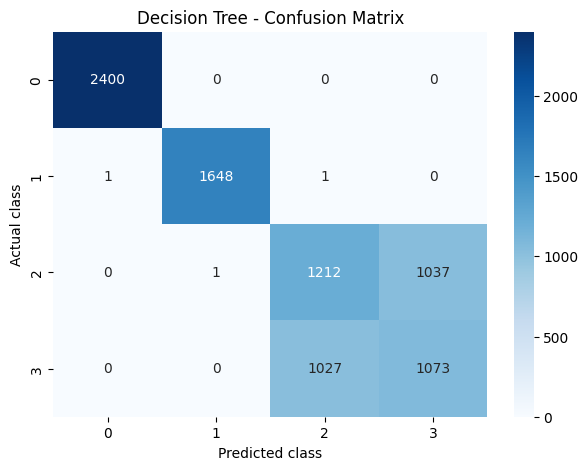

In [ ]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

In [ ]:
param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [3, 5, 10, 15, 20, None],
    "min_samples_split": [2, 10, 20, 50],
    "min_samples_leaf": [1, 5, 10, 20]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(grid_search.best_params_)

print("\nMejor F1 macro en validación cruzada:")
print(grid_search.best_score_)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits
Mejores hiperparámetros:
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}

Mejor F1 macro en validación cruzada:
0.7594012488096749


In [ ]:
best_dt = grid_search.best_estimator_

val_results = evaluate_model(
    best_dt,
    X_val,
    y_val,
    "Validation"
)

print(pd.DataFrame([val_results]))

      Dataset  Accuracy  Precision    Recall  F1-score
0  Validation  0.750833   0.758805  0.758622   0.75865


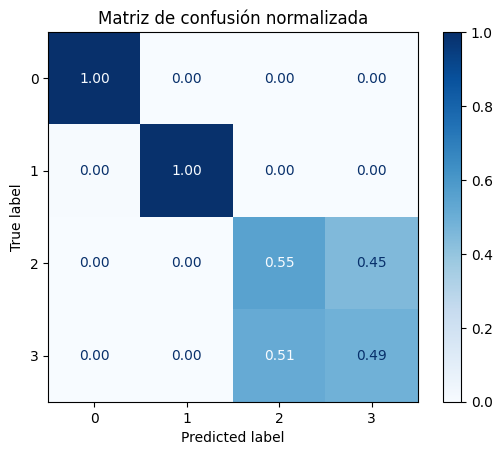

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = best_dt.predict(X_val)

cm = confusion_matrix(
    y_val,
    y_pred,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_dt.classes_
)

disp.plot(cmap="Blues", values_format=".2f")
plt.title("Matriz de confusión normalizada")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2400
           1       1.00      1.00      1.00      1650
           2       0.54      0.55      0.54      2250
           3       0.50      0.49      0.50      2100

    accuracy                           0.75      8400
   macro avg       0.76      0.76      0.76      8400
weighted avg       0.75      0.75      0.75      8400



In [ ]:
# Unir entrenamiento y validación
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

# Entrenar modelo final
final_dt = DecisionTreeClassifier(
    **grid_search.best_params_,
    random_state=42
)

final_dt.fit(X_train_final, y_train_final)

# Evaluación final
test_results = evaluate_model(
    final_dt,
    X_test,
    y_test,
    "Test"
)

print(pd.DataFrame([test_results]))

print("\nClassification Report:")
print(classification_report(y_test, final_dt.predict(X_test)))

  Dataset  Accuracy  Precision    Recall  F1-score
0    Test  0.739762   0.748215  0.748123  0.748155

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2400
           1       1.00      1.00      1.00      1650
           2       0.52      0.52      0.52      2250
           3       0.48      0.47      0.48      2100

    accuracy                           0.74      8400
   macro avg       0.75      0.75      0.75      8400
weighted avg       0.74      0.74      0.74      8400



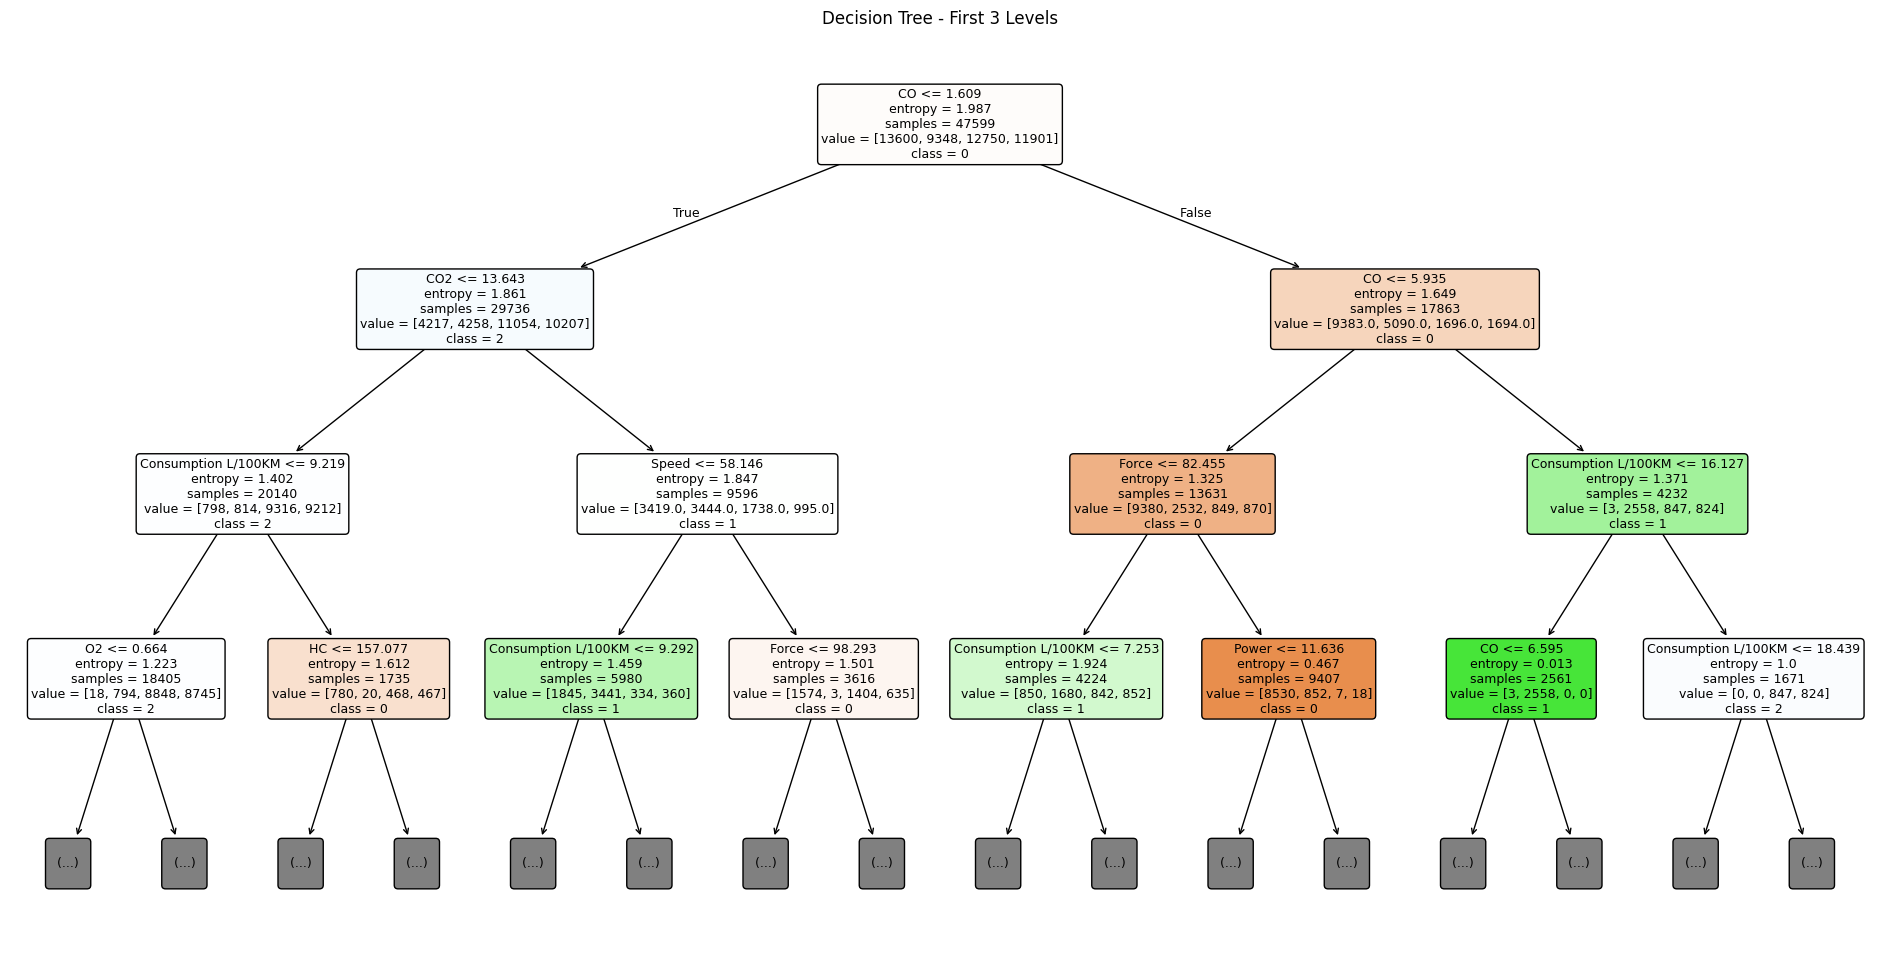

In [ ]:
plt.figure(figsize=(24, 12))

plot_tree(
    final_dt,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree - First 3 Levels")
plt.show()

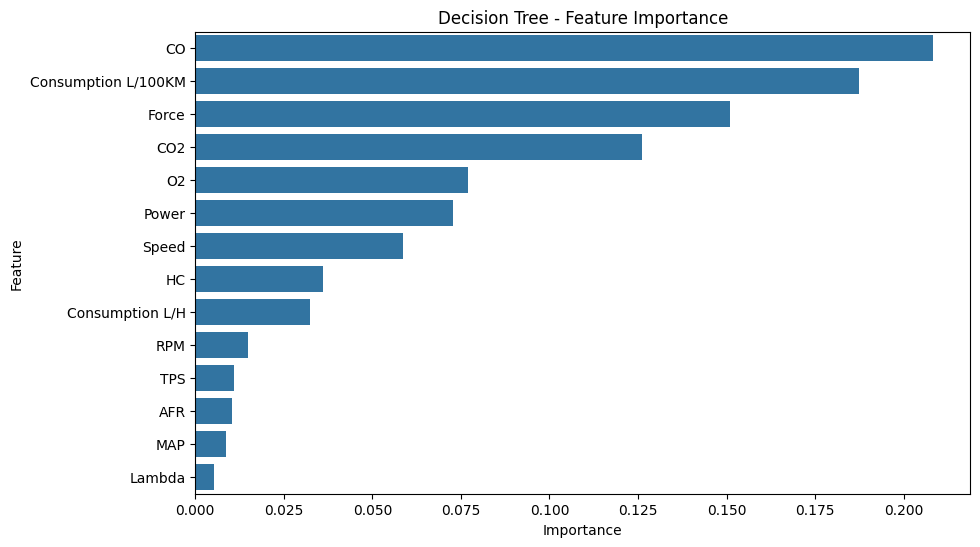

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_dt.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [ ]:
print("Mejores hiperparámetros:")
print(grid_search.best_params_)

print("\nProfundidad del árbol:")
print(best_dt.get_depth())

print("\nNúmero de hojas:")
print(best_dt.get_n_leaves())

Mejores hiperparámetros:
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}

Profundidad del árbol:
62

Número de hojas:
2775


#Random Forest

In [ ]:
# Predictores y variable objetivo
X = df.drop(columns=["Fault"])
y = df["Fault"]

# Debemos conservar las particiones 70/15/15
# que ya utilizaste para los demás modelos.

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(39199, 14)
(8400, 14)
(8400, 14)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

# Crear modelo
rf_base = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Entrenar
rf_base.fit(X_train, y_train)

# Predicciones
y_train_pred = rf_base.predict(X_train)
y_val_pred = rf_base.predict(X_val)

In [ ]:
def evaluate_model(y_true, y_pred, dataset):
    return {
        "Dataset": dataset,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro"
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro"
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="macro"
        )
    }

results_rf = pd.DataFrame([
    evaluate_model(y_train, y_train_pred, "Training"),
    evaluate_model(y_val, y_val_pred, "Validation")
])

print(results_rf)

      Dataset  Accuracy  Precision    Recall  F1-score
0    Training  1.000000    1.00000  1.000000  1.000000
1  Validation  0.747857    0.75604  0.756024  0.755983


In [ ]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

param_distributions = {
    "n_estimators": [150, 250, 400],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", None],
    "criterion": ["gini", "entropy"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    random_state=42,
    refit=True
)

random_search.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(random_search.best_params_)

print("Mejor F1 macro en CV:")
print(random_search.best_score_)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Mejores hiperparámetros:
{'n_estimators': 400, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 40, 'criterion': 'gini'}
Mejor F1 macro en CV:
0.7568666218899947


In [19]:
best_rf = random_search.best_estimator_

# Predicciones
y_train_pred_rf = best_rf.predict(X_train)
y_val_pred_rf = best_rf.predict(X_val)

results_best_rf = pd.DataFrame([
    evaluate_model(y_train, y_train_pred_rf, "Training"),
    evaluate_model(y_val, y_val_pred_rf, "Validation")
])

print(results_best_rf)

      Dataset  Accuracy  Precision    Recall  F1-score
0    Training  0.996684   0.996741  0.996797  0.996769
1  Validation  0.748333   0.756450  0.756681  0.756565


In [20]:
print(classification_report(
    y_val,
    y_val_pred_rf
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2400
           1       1.00      1.00      1.00      1650
           2       0.53      0.53      0.53      2250
           3       0.50      0.50      0.50      2100

    accuracy                           0.75      8400
   macro avg       0.76      0.76      0.76      8400
weighted avg       0.75      0.75      0.75      8400



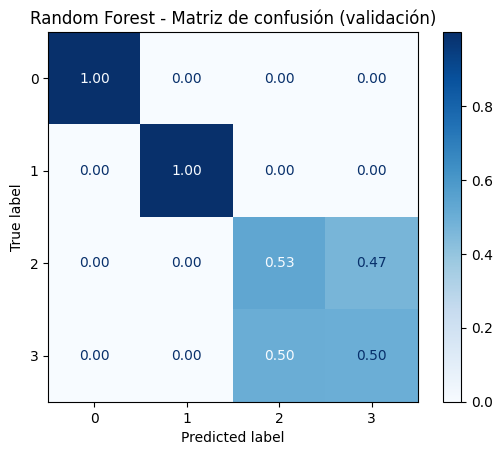

In [21]:
cm = confusion_matrix(
    y_val,
    y_val_pred_rf,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_rf.classes_
)

disp.plot(cmap="Blues", values_format=".2f")
plt.title("Random Forest - Matriz de confusión (validación)")
plt.show()

In [22]:
# Combinar entrenamiento y validación
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Crear modelo final
final_rf = RandomForestClassifier(
    **random_search.best_params_,
    random_state=42,
    n_jobs=-1
)

# Entrenar
final_rf.fit(X_train_val, y_train_val)

# Evaluar en test
y_test_pred_rf = final_rf.predict(X_test)

print(classification_report(
    y_test,
    y_test_pred_rf
))

results_test_rf = pd.DataFrame([
    evaluate_model(y_test, y_test_pred_rf, "Test")
])

print(results_test_rf)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2400
           1       1.00      1.00      1.00      1650
           2       0.52      0.51      0.52      2250
           3       0.49      0.51      0.50      2100

    accuracy                           0.74      8400
   macro avg       0.75      0.75      0.75      8400
weighted avg       0.74      0.74      0.74      8400

  Dataset  Accuracy  Precision    Recall  F1-score
0    Test   0.74381   0.752655  0.752457  0.752477


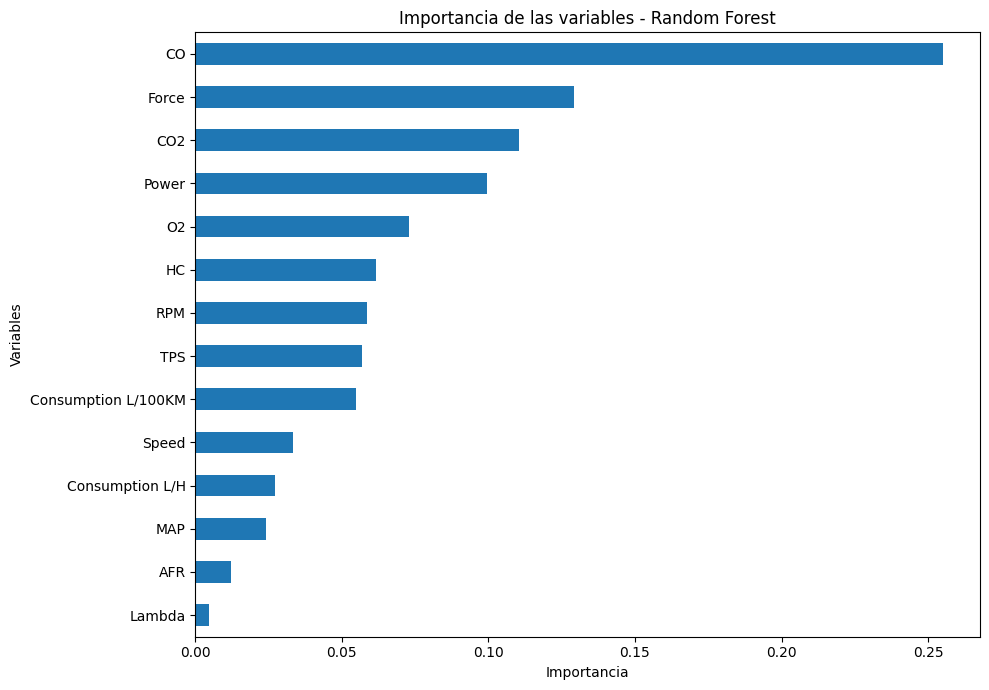

In [23]:
importances = pd.Series(
    final_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
importances.plot(kind="barh")

plt.title("Importancia de las variables - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

In [24]:
print("Mejores hiperparámetros:")
print(random_search.best_params_)

print("\nMejor F1 macro en validación cruzada:")
print(random_search.best_score_)

print("\nNúmero de árboles:")
print(len(best_rf.estimators_))

Mejores hiperparámetros:
{'n_estimators': 400, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 40, 'criterion': 'gini'}

Mejor F1 macro en validación cruzada:
0.7568666218899947

Número de árboles:
400


In [25]:
print(classification_report(y_val, y_val_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2400
           1       1.00      1.00      1.00      1650
           2       0.53      0.53      0.53      2250
           3       0.50      0.50      0.50      2100

    accuracy                           0.75      8400
   macro avg       0.76      0.76      0.76      8400
weighted avg       0.75      0.75      0.75      8400

